2. Import Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

3. Load the Dataset

In [2]:
df = pd.read_csv("Iris.csv")

print(df.head())
print(df.shape)

   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa
(150, 6)


4. Check Missing Values

In [3]:
print(df.isnull().sum())

Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64


5. Select Features and Target
Important: Do not use Id because it has no meaningful relationship with the flower species.

In [4]:
X = df[['SepalLengthCm',
        'SepalWidthCm',
        'PetalLengthCm',
        'PetalWidthCm']]

y = df['Species']

So:
X=Flower measurements
y=Species

6. Split Dataset into Training and Testing
Use 80% training and 20% testing.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 120
Testing samples: 30


7. Feature Scaling
This is an important step in KNN because KNN uses distance.

In [6]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

KNN calculates the distance between data points. Therefore, feature scaling prevents a feature with a larger numerical range from dominating the distance calculation.

8. Apply KNN
Let's initially choose: K=5

In [7]:
knn = KNeighborsClassifier(n_neighbors=5,)

knn.fit(X_train_scaled, y_train)

KNeighborsClassifier()

9. Make Predictions

In [8]:
y_pred = knn.predict(X_test_scaled)

print(y_pred)

['Iris-setosa' 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor'
 'Iris-setosa' 'Iris-versicolor' 'Iris-setosa' 'Iris-setosa'
 'Iris-virginica' 'Iris-versicolor' 'Iris-virginica' 'Iris-virginica'
 'Iris-virginica' 'Iris-versicolor' 'Iris-setosa' 'Iris-setosa'
 'Iris-setosa' 'Iris-versicolor' 'Iris-versicolor' 'Iris-versicolor'
 'Iris-setosa' 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor'
 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor' 'Iris-setosa'
 'Iris-virginica' 'Iris-setosa']


10. Calculate Accuracy

In [ ]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy (%):", accuracy * 100)


Accuracy: 0.9333333333333333
Accuracy (%): 93.33333333333333


11. Confusion Matrix

In [10]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]


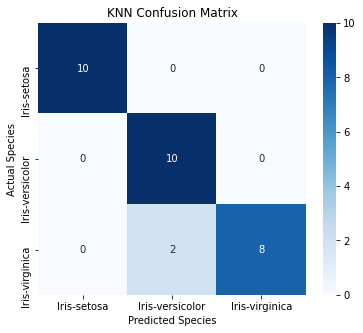

In [11]:
import seaborn as sns

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=knn.classes_,
    yticklabels=knn.classes_
)

plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.title("KNN Confusion Matrix")

plt.show()

12. Classification Report
It gives:

Precision

Recall

F1-score

Support


In [12]:
print(classification_report(y_test, y_pred))

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.83      1.00      0.91        10
 Iris-virginica       1.00      0.80      0.89        10

       accuracy                           0.93        30
      macro avg       0.94      0.93      0.93        30
   weighted avg       0.94      0.93      0.93        30



13. Predict a New Flower 🌸
| Feature      | Value |
| ------------ | ----: |
| Sepal Length |   5.1 |
| Sepal Width  |   3.5 |
| Petal Length |   1.4 |
| Petal Width  |   0.2 |

This is:

[5.1, 3.5, 1.4, 0.2]

In [13]:
new_flower = [[5.1, 3.5, 1.4, 0.2]]

new_flower_scaled = scaler.transform(new_flower)

prediction = knn.predict(new_flower_scaled)

print("Predicted Species:", prediction[0])

Predicted Species: Iris-setosa


15. Demonstrate the Effect of K
Instead of using only K=5, test several K values.

In [14]:
for k in [1, 3, 5, 7, 9, 11]:
    
    knn = KNeighborsClassifier(n_neighbors=k)
    
    knn.fit(X_train_scaled, y_train)
    
    y_pred = knn.predict(X_test_scaled)
    
    accuracy = accuracy_score(y_test, y_pred)
    
    print("K =", k, 
          "Accuracy =", round(accuracy * 100, 2), "%")

K = 1 Accuracy = 96.67 %
K = 3 Accuracy = 93.33 %
K = 5 Accuracy = 93.33 %
K = 7 Accuracy = 96.67 %
K = 9 Accuracy = 96.67 %
K = 11 Accuracy = 96.67 %


16. Plot Accuracy vs K

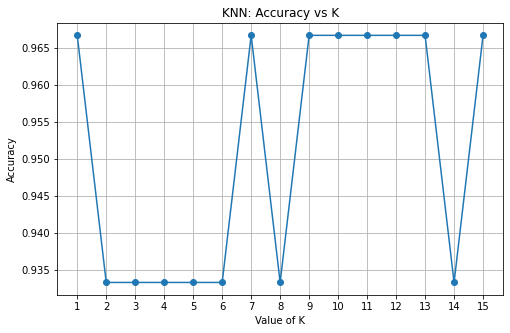

In [15]:
k_values = range(1, 16)
accuracies = []

for k in k_values:
    
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    
    y_pred = knn.predict(X_test_scaled)
    
    accuracy = accuracy_score(y_test, y_pred)
    accuracies.append(accuracy)

plt.figure(figsize=(8, 5))

plt.plot(k_values, accuracies, marker='o')

plt.xlabel("Value of K")
plt.ylabel("Accuracy")
plt.title("KNN: Accuracy vs K")
plt.xticks(k_values)
plt.grid()

plt.show()